### Verify setup before starting

In [2]:
from pathlib import Path
import pandas as pd
DATA_ROOT = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
split_df = pd.read_csv(SPLIT_FILE)
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


# A. Define the task and inspect the volumes

* State the input, output, unit of analysis and intended technical use. Distinguish a voxel, slice, volume and patient case

The input is going to be 4 channel volumes: Flair, T1-weighted, T1 contrast-enhanced and T2 weighted. Combined with depth, width and height, the input is a vector with dimensions (4, H, W, D). Our output is a binary segmentation mask for every voxel, meaning it will be of the dimension (H, W, D). The unit of analysis is going to be the voxel, as this is what we mask and what the modle is classifying. Additionally, we cannot share voxels from the same patient among our train, validation or test sets. The intended technical use is to build an end-to-end pipeline that educationally teaches and demonstrates how to do image segmentation for MRI. 

A voxel is a 3D pixel. A slice is a 2d sheet of voxels, so has Height, width and depth of 1 voxel unit. A volume will be a slice but with D voxels as depth. A patient case is 4 channels worth of volumes plus the segmentation label. 

------------------------------------------------------------------------------------------------------------------------------------------------

* Load at least three cases. Report array shape, channel order, affine matrix, orientation codes, voxel spacing and
label values.

In [3]:
#Get the first 3 training samples
'''
BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz
'''

'''
From dataset.json:

"modality": { 
	 "0": "FLAIR", 
	 "1": "T1w", 
	 "2": "t1gd",
	 "3": "T2w"
 }
 This is the channel order above^

'''






#Import library that can read the data
import nibabel as nib
import numpy as np
DATASET_PATH = "Task01_BrainTumour/"
case_paths = [("imagesTr/BRATS_001.nii.gz", "labelsTr/BRATS_001.nii.gz"), ("imagesTr/BRATS_003.nii.gz","labelsTr/BRATS_003.nii.gz"), ("imagesTr/BRATS_004.nii.gz","labelsTr/BRATS_004.nii.gz")]
for patient in case_paths:
    volume_path, label_path = DATASET_PATH + patient[0], DATASET_PATH + patient[1]
    volume = nib.load(volume_path)
    label = nib.load(label_path)

    print(f"Image: {volume_path}")
    print(f"Label: {label_path}")

    print(f"Image shape: {volume.shape}")
    print(f"Label shape: {label.shape}")

    print(f"Image voxel spacing: {volume.header.get_zooms()}")
    print(f"Label voxel spacing: {label.header.get_zooms()}")

    print(f"Affine matrix: \n{volume.affine}")

    print(f"Orientation codes: {nib.aff2axcodes(volume.affine)}")

    label_data = label.get_fdata()
    print(f"Label values: {np.unique(label_data)}")


del label_data, label_path, volume, volume_path, label




Image: Task01_BrainTumour/imagesTr/BRATS_001.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_001.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0, 1.0, 1.0)
Affine matrix: 
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Label values: [0. 1. 2. 3.]
Image: Task01_BrainTumour/imagesTr/BRATS_003.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_003.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0, 1.0, 1.0)
Affine matrix: 
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Label values: [0. 1. 2. 3.]
Image: Task01_BrainTumour/imagesTr/BRATS_004.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_004.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0

------------------------------------------------------------------------------------------------------------------------------------------------

* For one case, display FLAIR, T1, T1ce and T2 at the same physical location, plus the reference mask. 

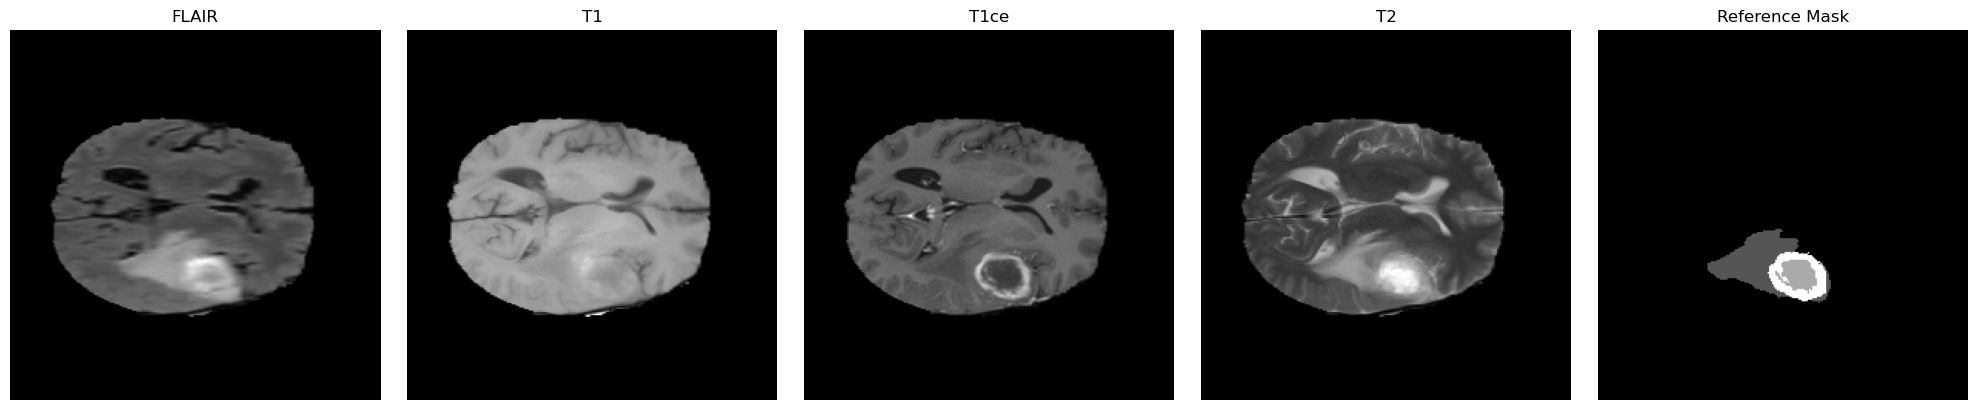

In [4]:
import matplotlib.pyplot as plt
case_1_volume = nib.load(DATASET_PATH + "imagesTr/BRATS_001.nii.gz")
case_1_label = nib.load(DATASET_PATH + "labelsTr/BRATS_001.nii.gz")

volume_data = case_1_volume.get_fdata()
label_data = case_1_label.get_fdata()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
z = volume_data.shape[2] // 2 #middle slice

axes[0].set_title("FLAIR")
axes[1].set_title("T1")
axes[2].set_title("T1ce")
axes[3].set_title("T2")
axes[4].set_title("Reference Mask")

axes[0].imshow(volume_data[:, :, z, 0], cmap="gray")
axes[1].imshow(volume_data[:, :, z, 1], cmap="gray")
axes[2].imshow(volume_data[:, :, z, 2], cmap="gray")
axes[3].imshow(volume_data[:, :, z, 3], cmap="gray")
axes[4].imshow(label_data[:, :, z], cmap="gray")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()



------------------------------------------------------------------------------------------------------------------------------------------------

* Display the reference in axial, coronal and sagittal planes and explain why file-index order alone is insufficient
for spatial interpretation.

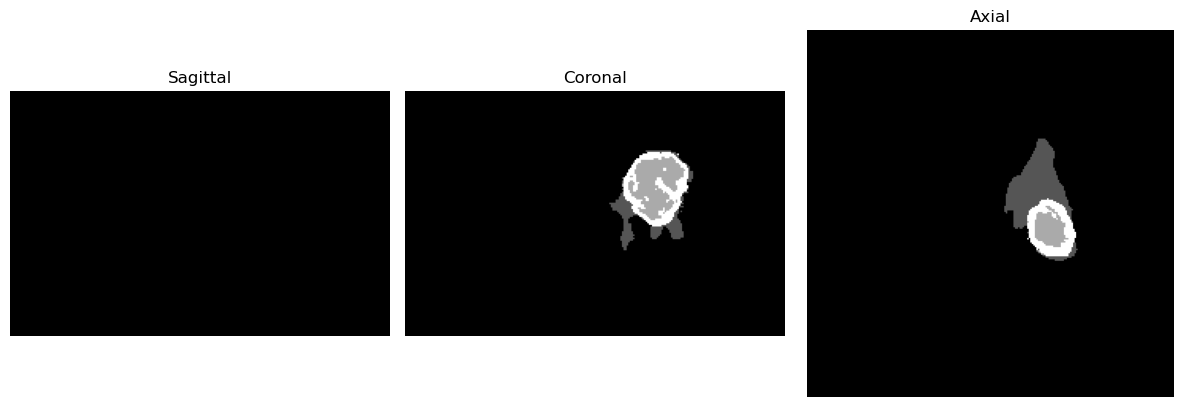

In [5]:
'''
We had orientation codes (R, A, S), meaning [x::] = sagittal, [:y:] = coronal, [::z] = axial.
'''


fig, axes = plt.subplots(1, 3, figsize=(12, 4))



sagittal = label_data[(label_data.shape[0] // 2),:,:]
coronal = label_data[:,(label_data.shape[1] // 2),:]
axial = label_data[:,:,(label_data.shape[2] // 2)]

axes[0].imshow(sagittal.T, cmap="gray")
axes[0].set_title("Sagittal")

axes[1].imshow(coronal.T, cmap="gray")
axes[1].set_title("Coronal")

axes[2].imshow(axial.T, cmap="gray")
axes[2].set_title("Axial")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



'''
Spatial interpretation needs the affine matrix to map. Essentially:

[x, y, z] = A[i, j, k] where xyz is the spatial location and ijk are the array coordinates. As an array difference of 1 could correspond to any difference between real voxels.

'''
del sagittal, coronal, axial

------------------------------------------------------------------------------------------------------------------------------------------------

# B. Create a reproducible split

* Use the supplied assignment2 split.csv exactly. Do not create a slice-level or patch-level split. 

In [6]:
train_df = split_df[split_df["split"] == "train"]
validation_df   = split_df[split_df["split"] == "validation"]
test_df  = split_df[split_df["split"] == "test"]

------------------------------------------------------------------------------------------------------------------------------------------------

* Verify that every listed image and label exists and that case identifiers are disjoint across train, validation and
test.

In [7]:
#First check every listed image and label exists
for _, row in split_df.iterrows():

    image_path = Path(DATASET_PATH + row["image_relpath"])
    label_path = Path(DATASET_PATH + row["label_relpath"])

    assert image_path.exists()
    assert label_path.exists()

#Now check no patient leakage
train_set = set(split_df[split_df["split"] == "train"]["case_id"])
validation_set = set(split_df[split_df["split"] == "validation"]["case_id"])
test_set = set(split_df[split_df["split"] == "test"]["case_id"])

assert train_set.isdisjoint(test_set)
assert train_set.isdisjoint(validation_set)
assert validation_set.isdisjoint(test_set)

del train_set, validation_set, test_set

------------------------------------------------------------------------------------------------------------------------------------------------

* Report case counts and the distribution of reference tumor volume in each split. Keep the test labels unused
until final evaluation.

Train case count: 338
Validation case count: 73
Test case count: 73


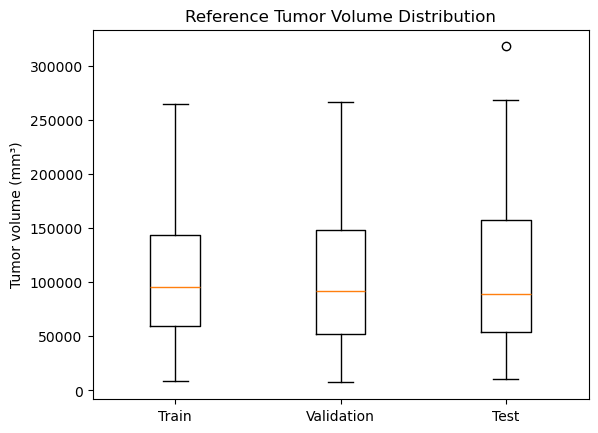

In [8]:
#First report case counts

print(f"Train case count: {len(train_df)}")
print(f"Validation case count: {len(validation_df)}")
print(f"Test case count: {len(test_df)}")

#Then describe distribution of reference tumor volume per split

tumor_volumes = list()

for _, row in split_df.iterrows():

    label = nib.load(DATASET_PATH + row["label_relpath"])
    label_data = label.get_fdata()

    tumor_voxels = np.sum(label_data > 0) #Everything becomes either true or false after label_data > 0, hence summing here gives voxel count that has tumor

    voxel_volume = np.prod(label.header.get_zooms()[:3]) #Get the actual voxel dimension reference and multiply them together to get volume 1 voxel takes up

    tumor_volume = tumor_voxels * voxel_volume

    tumor_volumes.append((row["split"],tumor_volume))


train_volumes = [v for split, v in tumor_volumes if split == "train"]
val_volumes   = [v for split, v in tumor_volumes if split == "validation"]
test_volumes  = [v for split, v in tumor_volumes if split == "test"]

plt.boxplot([train_volumes, val_volumes, test_volumes])
plt.xticks([1, 2, 3], ["Train", "Validation", "Test"])
plt.ylabel("Tumor volume (mm³)")
plt.title("Reference Tumor Volume Distribution")
plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

# C. Preprocess MRI and labels safely

* Verify geometry across all four channels and the label. If resampling is needed, define one target grid and
document it.

In [9]:
for _, row in split_df.iterrows():

    image = nib.load(DATASET_PATH + row["image_relpath"])
    label = nib.load(DATASET_PATH + row["label_relpath"])

    assert image.shape[:3] == label.shape

    assert np.allclose(image.header.get_zooms()[:3], label.header.get_zooms()[:3])

    assert np.allclose(image.affine, label.affine)
print("All MRI volumes and labels have matching geometry.")

All MRI volumes and labels have matching geometry.


------------------------------------------------------------------------------------------------------------------------------------------------

* Use linear interpolation for MRI and nearest-neighbour interpolation for labels. Demonstrate that label values
remain valid.

In [10]:
'''
I do not exactly know WHY we need to interpolate anything? Given that the geometries match up. In any case, I will make functions here that can do it in case for the future.
'''
from scipy.ndimage import zoom

def resample_mri(data, zoom_factor):
    return zoom(data, (*zoom_factor, 1), order=1) #Example usage is zoom_factor = (0.5, 0.5, 0.5). (240, 240, 155, 4) -> (120, 120, 78, 4)

def resample_label(data, zoom_factor):
    return zoom(data, zoom_factor, order=0)

example_array = np.array([
    [0, 0, 1, 2],
    [2, 3, 0, 1],
    [2, 1, 0, 3],
    [0, 1, 0, 0],

])
resampled = resample_label(example_array, (0.5, 0.5))
print("Original values:", np.unique(example_array))
print("Resampled values:", np.unique(resampled))
#See how they are a subset



del example_array, resampled




Original values: [0 1 2 3]
Resampled values: [0 2]


------------------------------------------------------------------------------------------------------------------------------------------------

* Normalize each MRI channel using statistics from non-zero brain voxels, not the zero-padded background. Report
the resulting mean and standard deviation. 

In [20]:
means = [0, 0, 0, 0]
stds = [0, 0, 0, 0]
counts = [0, 0, 0, 0]

for _, row in train_df.iterrows():

    image = nib.load(DATASET_PATH + row["image_relpath"])
    image_data = image.get_fdata()

    for channel in range(4):

        channel_data = image_data[:, :, :, channel]

        brain_voxels = channel_data[channel_data != 0]

        means[channel] += np.sum(brain_voxels)
        stds[channel] += np.sum(brain_voxels ** 2)
        counts[channel] += len(brain_voxels)

for channel in range(4):
    means[channel] /= counts[channel]
    stds[channel] = np.sqrt(stds[channel] / counts[channel] - means[channel] ** 2)


channels = ["FLAIR", "T1", "T1ce", "T2"]



Continuation below as the above takes a minute to run

In [21]:
for channel in range(4):
    print(f"Channel: {channels[channel]}\n mean: {means[channel]}\n std: {stds[channel]}")

#Now do the normalising
def normalise(image):
    normalised = np.zeros_like(image)

    for channel in range(4):
        normalised[:,:,:,channel] = np.where(image[:,:,:,channel] == 0, 0, (image[:,:,:,channel] - means[channel]) / stds[channel])

    return normalised

'''Note just planning ahead the actual normalising happens in the dataset and dataloader'''



Channel: FLAIR
 mean: 464.9858864745449
 std: 270.2428220084918
Channel: T1
 mean: 613.3651687800044
 std: 331.28203722243865
Channel: T1ce
 mean: 616.2871196537117
 std: 391.1857794860021
Channel: T2
 mean: 489.1851223394134
 std: 287.796171497187


'Note just planning ahead the actual normalising happens in the dataset and dataloader'

------------------------------------------------------------------------------------------------------------------------------------------------

* Crop or pad consistently and apply safe training-only augmentation. Show one paired before/after example and
justify the transforms.

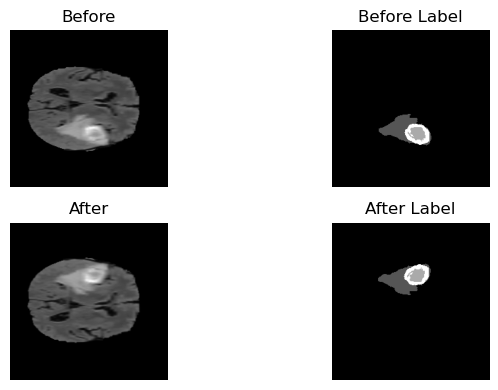

In [22]:
from scipy.ndimage import rotate
class RandomFlip:

    def __init__(self, probability=0.5):
        self.probability = probability

    def __call__(self, image, label):

        if np.random.random() < self.probability:
            image = np.flip(image, axis=0).copy() #Sagittal flip
            label = np.flip(label, axis=0).copy() #Also flip label to match

        return image, label

class Rotation:

    def __init__(self, degrees=10):
            self.degrees = degrees
    
    def __call__(self, image, label):
    
        angle = np.random.uniform(-self.degrees, self.degrees)

        for channel in range(4):

            image[:, :, :, channel] = rotate(image[:, :, :, channel],angle,reshape=False,order=1, axes=(0,1))

        label = rotate(label, angle, reshape=False, order=0,  axes=(0,1))
        return image, label

class Transforms:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, image, label):
        for transform in self.transforms:
            image, label = transform(image, label)
        return image, label     

#Show a before and after

case_1_volume = nib.load(DATASET_PATH + "imagesTr/BRATS_001.nii.gz")
case_1_label = nib.load(DATASET_PATH + "labelsTr/BRATS_001.nii.gz")

data = case_1_volume.get_fdata()
label = case_1_label.get_fdata()

slice = data.shape[2] // 2

after_image, after_label = Rotation(10)(data.copy(), label.copy())
after_image, after_label = RandomFlip(0.25)(after_image, after_label)

before_image = data[:, :, data.shape[2] // 2, 0]  
before_label = label[:, :, data.shape[2] // 2]

after_image = after_image[:, :, data.shape[2] // 2, 0]
after_label = after_label[:, :, data.shape[2] // 2]

plt.figure(figsize=(8, 4))

plt.subplot(2, 2, 1)
plt.imshow(before_image, cmap="gray")
plt.title("Before")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(before_label, cmap="gray")
plt.title("Before Label")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(after_image, cmap="gray")
plt.title("After")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(after_label, cmap="gray")
plt.title("After Label")
plt.axis("off")

plt.tight_layout()
plt.show()






------------------------------------------------------------------------------------------------------------------------------------------------

# D. Implement patch-based volumetric training

* Implement a PyTorch Dataset and DataLoader returning tensors shaped [C, D, H, W ] and binary masks shaped
[1, D, H, W ]. Print and verify one batch. 

In [23]:
import torch
from torch.utils.data import Dataset, DataLoader

class BrainTumorDataset(Dataset):

    def __init__(self, dataframe, means=means, stds=stds, transform=None, path=DATASET_PATH):
        self.dataframe = dataframe
        self.path = path
        self.means = means
        self.stds = stds
        self.transform = transform

        

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = nib.load(self.path + row["image_relpath"])
        image = image.get_fdata(dtype=np.float32)

        label = nib.load(self.path + row["label_relpath"])
        label = label.get_fdata(dtype=np.float32)

        label = (label > 0)

        #Then we have to normalise the image and apply the augmentations

        image = normalise(image=image)
        if self.transform is not None:
            #Apply transforms
            image, label = self.transform(image, label)

        #We are currently in (H, W, D, C) and we want (C, D, H, W)
        image = np.transpose(image, axes=(3, 2, 0, 1))

        #We are currently in (H, W, D) and we want (1, D, H, W)
        label = np.transpose(label, axes=(2, 0, 1))

        image = torch.from_numpy(image).to(torch.float32)
        label = torch.from_numpy(label).to(torch.float32)

        return image, label




'''
Now create the datasets
'''

train_dataset = BrainTumorDataset(train_df, transform=Transforms((RandomFlip(0.25), Rotation(10))))
validation_dataset = BrainTumorDataset(validation_df)
test_dataset = BrainTumorDataset(test_df)

'''
Now the dataloaders
'''
train_dataloader = DataLoader(train_dataset, batch_size=1, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=1, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False)


image, mask = next(iter(train_dataloader))

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image dtype:", image.dtype)
print("Mask dtype:", mask.dtype)

print("Unique mask values:", torch.unique(mask))
        

Image shape: torch.Size([1, 4, 155, 240, 240])
Mask shape: torch.Size([1, 155, 240, 240])
Image dtype: torch.float32
Mask dtype: torch.float32
Unique mask values: tensor([0., 1.])


------------------------------------------------------------------------------------------------------------------------------------------------

* Build a lightweight 3D U-Net or equivalent fully convolutional 3D model. Report input channels, output channels,
parameter count and patch size. 

In [24]:
import torch.nn as nn

class ConvLayer(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_channels=input_channels, out_channels=output_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(output_channels),
            nn.LeakyReLU(),
            nn.Conv3d(in_channels=output_channels, out_channels=output_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(output_channels),
            nn.LeakyReLU(),
        )

    def forward(self, x):
        return self.net(x)


'''
Okay the plan is going to be 4 channels --> 16--> 32--> 64 --> 128. Then go back up to 1 channel which is the output
We do this upscaling by upscaling by 2*, then concatinating prev layer activ into a conv layer that keeps dimension size.
'''
class UNET(nn.Module):
    def __init__(self, input_channels=4, base_channels=16, output_channels=1):
        super().__init__()
        c = base_channels
        self.l1 = ConvLayer(input_channels, c)
        self.l2 = ConvLayer(c, c * 2)
        self.l3 = ConvLayer(c * 2, c * 4)
        self.b = ConvLayer(c * 4, c * 8)
        self.pool = nn.MaxPool3d(2)

        self.up3 = nn.ConvTranspose3d(c * 8, c * 4, kernel_size=2, stride=2)
        self.dl3 = ConvLayer(c * 4 + c * 4, c * 4) #Go from 128 to 64

        self.up2 = nn.ConvTranspose3d(c * 4, c * 2, kernel_size=2, stride=2)
        self.dl2 = ConvLayer(c * 2 + c * 2, c * 2) #Go from 64 to 32

        self.up1 = nn.ConvTranspose3d(c * 2, c, kernel_size=2, stride=2)
        self.dl1 = ConvLayer(c + c, c) #now 16 out
        self.final = nn.Conv3d(c, output_channels, kernel_size=1)


    def forward(self, x):
        e1 = self.l1(x)
        e2 = self.l2(self.pool(e1))
        e3 = self.l3(self.pool(e2))
        bottleneck =  self.b(self.pool(e3))

        u3 = self.up3(bottleneck)                        
        d3 = self.dl3(torch.cat([u3, e3], dim=1)) 

        u2 = self.up2(d3)                        
        d2 = self.dl2(torch.cat([u2, e2], dim=1))

        u1 = self.up1(d2)                        
        d1 = self.dl1(torch.cat([u1, e1], dim=1))      
        return self.final(d1)       


model = UNET()
patch_size = (96, 96, 96)

x = torch.randn(1, 4, *patch_size)
y = model(x)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Input channels: ", x.shape[1])
print("Output channels: ", y.shape[1])
print("Patch size: ", patch_size)
print("Parameters: ", n_params)
del model

Input channels:  4
Output channels:  1
Patch size:  (96, 96, 96)
Parameters:  1401857


------------------------------------------------------------------------------------------------------------------------------------------------

* Train first with uniform random patches. State the loss, optimizer, learning rate, epoch/iteration budget and
random seed.

In [ ]:
import random
import torch.nn.functional as F
def set_seed(seed=100):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

""" 
Okay, get H, W, D. My patch size is 96, so the max coord my patch can start 
is H - 96,  - 96, D - 96. 
"""
def random_corner(shape, P):
    D, H, W = shape
    d0 = np.random.randint(0, D - P + 1)
    h0 = np.random.randint(0, H - P + 1)
    w0 = np.random.randint(0, W - P + 1)
    return (d0, h0, w0)

def get_patch(image, mask, P):
    D, H, W = mask.shape
    d0, h0, w0 = random_corner((D, H, W), P)
    img_patch  = image[:, d0 : d0 + P, h0 : h0 + P, w0 : w0 + P]
    mask_patch = mask[d0 : d0 + P, h0 : h0 + P, w0 : w0 + P]
    return img_patch, mask_patch










#Loss func
bce = nn.BCEWithLogitsLoss()

def dice_loss(logits, target, eps=1e-6):
    probs = torch.sigmoid(logits)
    inter = (probs * target).sum()
    return 1 - (2 * inter + eps) / (probs.sum() + target.sum() + eps)

def loss_fn(logits, target):
    return bce(logits, target) + dice_loss(logits, target)

def dice_score(logits, target, eps=1e-6):
    pred = (torch.sigmoid(logits) > 0.5).float()
    inter = (pred * target).sum()
    return ((2 * inter + eps) / (pred.sum() + target.sum() + eps)).item()


@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    losses, dices = [], []
    for image, mask in loader:
        image, mask = image.to(device), mask.to(device)
        D, H, W = mask.shape[1:]
        x = F.pad(image, (0, (-W) % 8, 0, (-H) % 8, 0, (-D) % 8))   
        logits = model(x)[:, :, :D, :H, :W]                          
        y = mask.unsqueeze(1)
        losses.append(loss_fn(logits, y).item())
        dices.append(dice_score(logits, y))
    model.train()
    return float(np.mean(losses)), float(np.mean(dices))

#Training loop now

device = "mps" if torch.backends.mps.is_available() else "cpu"
set_seed(100)
model = UNET().to(device)
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

P = 96

epochs = 10
patches_seen, patches_with_tumor = 0, 0

fraction_tumor = []
train_losses, val_losses, val_dices = [], [], []     
best_dice = -1.0

for epoch in range(epochs):
    running = 0
    for image, mask in train_dataloader:
        image, mask = image[0], mask[0]          

        x, y = get_patch(image, mask, P)

        patches_seen += 1
        if y.sum() > 0:
            patches_with_tumor += 1


        fraction_tumor.append(y.mean().item())
        x = x.unsqueeze(0).to(device)
        y = y.unsqueeze(0).unsqueeze(0).to(device)

        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running += loss.item()

    mean_loss = running / len(train_dataloader)
    val_loss, val_dice = validate(model, validation_dataloader, device)

    train_losses.append(mean_loss)
    val_losses.append(val_loss)
    val_dices.append(val_dice)

    if val_dice > best_dice:                         
        best_dice = val_dice
        torch.save(model.state_dict(), 'model_uniform_best.pth')



    print(f"Epochs: {epoch + 1} / {epochs}, train loss:{mean_loss}, val loss:{val_loss}, val_dice: {val_dice}")


print("Fraction with tumor:", patches_with_tumor / patches_seen)
print("Mean tumor-voxel fraction:", sum(fraction_tumor) / len(fraction_tumor))



torch.save(model.state_dict(), 'model_uniform_last.pth')

    





Epochs: 1 / 10, train loss:1.1635933202751996, val loss:1.0133466238844884, val_dice: 0.5441327553712093
Epochs: 2 / 10, train loss:0.875902900505348, val loss:0.8091305388163214, val_dice: 0.5516090382453476
Epochs: 3 / 10, train loss:0.7680588578419573, val loss:0.7097256318347095, val_dice: 0.5092811767930445
Epochs: 4 / 10, train loss:0.7151084058207168, val loss:0.6142582642297222, val_dice: 0.5676288481750716
Epochs: 5 / 10, train loss:0.6677417819933779, val loss:0.6032746348479022, val_dice: 0.5414804004847187
Epochs: 6 / 10, train loss:0.6444690481886356, val loss:0.6072806501633501, val_dice: 0.5205349341443141
Epochs: 7 / 10, train loss:0.6478832453357045, val loss:0.5262388699267009, val_dice: 0.5901857264649529
Epochs: 8 / 10, train loss:0.6610967592066209, val loss:0.43041041197433866, val_dice: 0.6766632738178724
Epochs: 9 / 10, train loss:0.648255126054823, val loss:0.5380845143370432, val_dice: 0.5715568482059322
Epochs: 10 / 10, train loss:0.6252461753168402, val loss

------------------------------------------------------------------------------------------------------------------------------------------------

* Train the same model with tumor-aware patch sampling. Keep initialization and training budget controlled.
Report the fraction of sampled patches containing tumor for both samplers. 

In [25]:
#Saving the variables from before so I do NOT have to train that again
print(train_losses)
print("-------")
print(val_losses)
print("-------")
print(val_dices)
print("-------")
print(patches_with_tumor / patches_seen)
print("-------")
sum(fraction_tumor) / len(fraction_tumor)


NameError: name 'train_losses' is not defined

In [ ]:
#Save variables from above
u_train_losses = train_losses
u_val_losses = val_losses
u_val_dices = val_dices
u_frac_with_tumor = patches_with_tumor / patches_seen
u_mean_tumor_voxel = sum(fraction_tumor) / len(fraction_tumor)




def get_tumor_aware_patch(image, mask, P, prob=0.5):
    D, H, W = mask.shape
    if np.random.rand() < prob and mask.sum() > 0: #If there is tumor in the mask and we coin flip
        coords = torch.nonzero(mask)  #Will have N rows, 3 columns of d, h, w               
        center = coords[np.random.randint(len(coords))]
        cd, ch, cw = int(center[0]), int(center[1]), int(center[2])
        d0 = min(max(cd - P // 2, 0), D - P)
        h0 = min(max(ch - P // 2, 0), H - P)
        w0 = min(max(cw - P // 2, 0), W - P)

    else:
        d0, h0, w0 = random_corner((D, H, W), P)

    img_patch  = image[:, d0:d0+P, h0:h0+P, w0:w0+P]
    mask_patch = mask[d0:d0+P, h0:h0+P, w0:w0+P]
    return img_patch, mask_patch




#Training loop now: exactly as above but change patch sampling

device = "mps" if torch.backends.mps.is_available() else "cpu"
set_seed(100)
model = UNET().to(device)
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

P = 96

epochs = 10
patches_seen, patches_with_tumor = 0, 0

fraction_tumor = []
train_losses, val_losses, val_dices = [], [], []     
best_dice = -1.0

for epoch in range(epochs):
    running = 0
    for image, mask in train_dataloader:
        image, mask = image[0], mask[0]          

        x, y = get_tumor_aware_patch(image, mask, P)

        patches_seen += 1
        if y.sum() > 0:
            patches_with_tumor += 1


        fraction_tumor.append(y.mean().item())
        x = x.unsqueeze(0).to(device)
        y = y.unsqueeze(0).unsqueeze(0).to(device)

        logits = model(x)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running += loss.item()

    mean_loss = running / len(train_dataloader)
    val_loss, val_dice = validate(model, validation_dataloader, device)

    train_losses.append(mean_loss)
    val_losses.append(val_loss)
    val_dices.append(val_dice)

    if val_dice > best_dice:                         
        best_dice = val_dice
        torch.save(model.state_dict(), 'model_aware_best.pth')



    print(f"Epochs: {epoch + 1} / {epochs}, train loss:{mean_loss}, val loss:{val_loss}, val_dice: {val_dice}")


print("Fraction with tumor:", patches_with_tumor / patches_seen)
print("Mean tumor-voxel fraction:", sum(fraction_tumor) / len(fraction_tumor))
torch.save(model.state_dict(), 'model_aware_last.pth')


Epochs: 1 / 10, train loss:1.1086514809075192, val loss:1.0700991333347478, val_dice: 0.3818117231323045
Epochs: 2 / 10, train loss:0.7533753822893786, val loss:0.8782797186342004, val_dice: 0.47321451580381557
Epochs: 3 / 10, train loss:0.6112737806414711, val loss:0.807251753464137, val_dice: 0.47550465906523676
Epochs: 4 / 10, train loss:0.5818503664795464, val loss:0.6923939671418439, val_dice: 0.5403610798378781
Epochs: 5 / 10, train loss:0.5392606965095333, val loss:0.6355812994584645, val_dice: 0.5545204008789095
Epochs: 6 / 10, train loss:0.5327662212123885, val loss:0.6907127803727372, val_dice: 0.48527371730298213
Epochs: 7 / 10, train loss:0.48837515603772985, val loss:0.6230237496225801, val_dice: 0.533611593410781
Epochs: 8 / 10, train loss:0.5319609229381268, val loss:0.5998977181846148, val_dice: 0.5397805721333174
Epochs: 9 / 10, train loss:0.44927720269243393, val loss:0.5480170699015056, val_dice: 0.6280963798761992
Epochs: 10 / 10, train loss:0.4597135998705435, val 

In [26]:
#Saving the variables from before so I do NOT have to train that again
print(train_losses)
print("-------")
print(val_losses)
print("-------")
print(val_dices)
print("-------")
print(patches_with_tumor / patches_seen)
print("-------")
sum(fraction_tumor) / len(fraction_tumor)

NameError: name 'train_losses' is not defined

------------------------------------------------------------------------------------------------------------------------------------------------

* Plot training and validation loss and validation Dice. Identify underfitting, instability or overfitting without
using test results for selection. 

In [27]:
#Uniform
u_train_losses = [1.1635933202751996, 0.875902900505348, 0.7680588578419573, 0.7151084058207168, 0.6677417819933779, 0.6444690481886356, 0.6478832453357045, 0.6610967592066209, 0.648255126054823, 0.6252461753168402]
u_val_losses   = [1.0133466238844884, 0.8091305388163214, 0.7097256318347095, 0.6142582642297222, 0.6032746348479022, 0.6072806501633501, 0.5262388699267009, 0.43041041197433866, 0.5380845143370432, 0.5645585313235244]
u_val_dices    = [0.5441327553712093, 0.5516090382453476, 0.5092811767930445, 0.5676288481750716, 0.5414804004847187, 0.5205349341443141, 0.5901857264649529, 0.6766632738178724, 0.5715568482059322, 0.5409681157349315]
u_frac_with_tumor  = 0.7926035502958579
u_mean_tumor_voxel = 0.039677972320854606

#Tumor Aware
a_train_losses = [1.1086514809075192, 0.7533753822893786, 0.6112737806414711, 0.5818503664795464, 0.5392606965095333, 0.5327662212123885, 0.48837515603772985, 0.5319609229381268, 0.44927720269243393, 0.4597135998705435]
a_val_losses   = [1.0700991333347478, 0.8782797186342004, 0.807251753464137, 0.6923939671418439, 0.6355812994584645, 0.6907127803727372, 0.6230237496225801, 0.5998977181846148, 0.5480170699015056, 0.4725279554928819]
a_val_dices    = [0.3818117231323045, 0.47321451580381557, 0.47550465906523676, 0.5403610798378781, 0.5545204008789095, 0.48527371730298213, 0.533611593410781, 0.5397805721333174, 0.6280963798761992, 0.6536948108560827]
a_frac_with_tumor  = 0.8958579881656805
a_mean_tumor_voxel = 0.07068220103149814

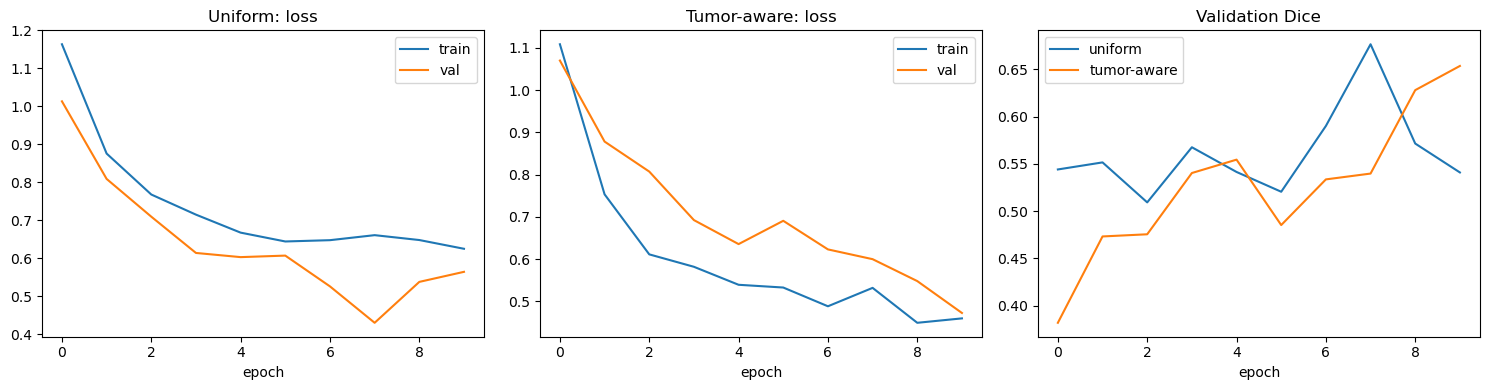

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))


ax[0].plot(u_train_losses, label="train")
ax[0].plot(u_val_losses, label="val")
ax[0].set_title("Uniform: loss")
ax[0].legend()


ax[1].plot(a_train_losses, label="train")
ax[1].plot(a_val_losses, label="val")
ax[1].set_title("Tumor-aware: loss")
ax[1].legend()


ax[2].plot(u_val_dices, label="uniform")
ax[2].plot(a_val_dices, label="tumor-aware")
ax[2].set_title("Validation Dice")
ax[2].legend()

for a in ax:
    a.set_xlabel("epoch")

plt.tight_layout()
plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

# E. Controlled sampling comparison

* Compare uniform and tumor-aware sampling using the same architecture, split, loss and training budget. 

This requires report comments (see report)

------------------------------------------------------------------------------------------------------------------------------------------------

* Report validation Dice, tumor sensitivity and false-positive volume for both conditions. Explain the mechanism
behind any difference.

In [33]:
# Readd device = mps as this is only done in the training cells and I don't want to spend another x hours training
import torch.nn.functional as F
device = "mps" if torch.backends.mps.is_available() else "cpu"

@torch.no_grad()
def calculate_Sensitivity_falsep(ckpt):
    m = UNET().to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.eval()
    sensitivity, falsep = [], []

    for i, (image, mask) in enumerate(validation_dataloader):   #shuffle=False so i matches validation_df
        image, mask = image.to(device), mask.to(device)
        D, H, W = mask.shape[1:]

        
        x = F.pad(image, (0, (-W) % 8, 0, (-H) % 8, 0, (-D) % 8))

       
        pred = torch.sigmoid(m(x)[:, 0, :D, :H, :W]) > 0.5
        true = mask > 0.5

        
        tp  = (pred & true).sum().item()      
        fn  = (~pred & true).sum().item()     
        fpv = (pred & ~true).sum().item()     

        #Volume of one voxel in mm^3 from the file header
        vox = float(np.prod(nib.load(DATASET_PATH + validation_df.iloc[i]["image_relpath"]).header.get_zooms()[:3]))

        sensitivity.append(tp / (tp + fn) if tp + fn > 0 else np.nan)  
        falsep.append(fpv * vox / 1000)                              

    return np.nanmean(sensitivity), np.mean(falsep)

for name, ckpt, die in [("Uniform",     "model_uniform_best.pth", u_val_dices),("Tumor-aware", "model_aware_best.pth",   a_val_dices)]:
    s, f = calculate_Sensitivity_falsep(ckpt)
    print(f"{name}: Dice: {max(die)}, Sensitivity: {s}, False Positive volume: {f} mm^3")

Uniform: Dice: 0.6766632738178724, Sensitivity: 0.8360380577131038, False Positive volume: 56.01134246575342 mm^3
Tumor-aware: Dice: 0.6536948108560827, Sensitivity: 0.7713128176176016, False Positive volume: 52.277794520547936 mm^3


------------------------------------------------------------------------------------------------------------------------------------------------

* Select one final configuration using validation evidence only. State one disadvantage of excessive tumor
oversampling.

This is done in the report

------------------------------------------------------------------------------------------------------------------------------------------------

# F. Reconstruct and evaluate full volumes

* Implement overlapping sliding-window inference and combine overlapping probabilities before thresholding.
State patch size, stride, overlap and blending rule. 

In [34]:
import os, time

PATCH = 96
PRED_DIR = "preds"


def window_starts(size, P, stride):
    starts = list(range(0, size - P + 1, stride))
    if starts[-1] + P < size:                     
        starts.append(size - P)
    return starts

@torch.no_grad()
def sliding_window_probs(model, image, P=PATCH, overlap=0.5):
   
    _, _, D, H, W = image.shape
    stride = max(1, int(round(P * (1 - overlap))))

    prob_sum = torch.zeros(D, H, W, device=image.device)
    count    = torch.zeros(D, H, W, device=image.device)

    for d0 in window_starts(D, P, stride):
        for h0 in window_starts(H, P, stride):
            for w0 in window_starts(W, P, stride):
                patch = image[:, :, d0:d0+P, h0:h0+P, w0:w0+P]
                prob = torch.sigmoid(model(patch))[0, 0]
                prob_sum[d0:d0+P, h0:h0+P, w0:w0+P] += prob
                count[d0:d0+P, h0:h0+P, w0:w0+P] += 1

    assert count.min() >= 1                          
    return (prob_sum / count).cpu()

def case_path(tag, case_id):
    return f"{PRED_DIR}/{tag}/{case_id}.npz"

def predict_and_cache(name, ckpt, loader, df, split, overlap=0.5, max_cases=None):
    """Run the model on every case in `loader` and save probs, mask and spacing to disk."""
    tag = f"{name}_{split}_ov{int(overlap * 100)}"
    os.makedirs(f"{PRED_DIR}/{tag}", exist_ok=True)

    m = UNET().to(device)
    m.load_state_dict(torch.load(ckpt, map_location=device))
    m.eval()

    t0 = time.time()
    for i, (image, mask) in enumerate(loader):       
        if max_cases is not None and i >= max_cases:
            break
        row = df.iloc[i]
        path = case_path(tag, row["case_id"])
        if os.path.exists(path):                    
            continue

        probs = sliding_window_probs(m, image.to(device), PATCH, overlap)
        spacing = nib.load(DATASET_PATH + row["image_relpath"]).header.get_zooms()[:3]
        np.savez_compressed(path,
                            probs=probs.numpy().astype(np.float16),
                            mask=(mask[0].numpy() > 0.5).astype(np.uint8),
                            spacing=np.array(spacing, dtype=np.float32))
    seconds = time.time() - t0
    print(f"{tag}: {seconds / 60} min")
    return tag, seconds

def load_case(tag, case_id):
    z = np.load(case_path(tag, case_id))
    return z["probs"].astype(np.float32), z["mask"].astype(bool), z["spacing"]

def cached_cases(tag):
    return sorted(f[:-4] for f in os.listdir(f"{PRED_DIR}/{tag}") if f.endswith(".npz"))














tags = {}
for name, ckpt in [("uniform", "model_uniform_best.pth"), ("aware", "model_aware_best.pth")]:
    tags[name], _ = predict_and_cache(name, ckpt, validation_dataloader, validation_df, "val", overlap=0.5)


for name, tag in tags.items():
    dices = []
    for cid in cached_cases(tag):
        p, t, _ = load_case(tag, cid)
        pred = p > 0.5                      
        dices.append(2 * (pred & t).sum() / (pred.sum() + t.sum() + 1e-6))
    print(f"{name}: mean Dice {np.mean(dices)} over {len(dices)} cases")


for size in (155, 240):
    print(size, window_starts(size, 96, 48))

uniform_val_ov50: 0.35494585037231446 min
aware_val_ov50: 0.3500542481740316 min
uniform: mean Dice 0.7070307478335954 over 73 cases
aware: mean Dice 0.680858006978957 over 73 cases
155 [0, 48, 59]
240 [0, 48, 96, 144]


------------------------------------------------------------------------------------------------------------------------------------------------

* On the untouched test split, report case-wise whole-tumor Dice, IoU, sensitivity and HD95 in millimetres.
Provide mean, standard deviation and median, plus the number of empty predictions. 

In [35]:
from scipy.ndimage import binary_erosion, distance_transform_edt

test_tags = {}
for name, ckpt in [("uniform", "model_uniform_best.pth")]:
    test_tags[name], _ = predict_and_cache(name, ckpt, test_dataloader, test_df, "test", overlap=0.5)

test_res = {}
for name, tag in test_tags.items():
    rows = []
    for cid in cached_cases(tag):
        probs, true, spacing = load_case(tag, cid)
        pred = probs > 0.5
        sp = (spacing[2], spacing[0], spacing[1])        

        tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()

        if pred.sum() == 0 or true.sum() == 0:
            hd = np.nan                                 
        else:
            ps, ts = binary_erosion(pred) ^ pred, binary_erosion(true) ^ true   
            d1 = distance_transform_edt(~ts, sampling=sp)[ps]
            d2 = distance_transform_edt(~ps, sampling=sp)[ts]
            hd = np.percentile(np.concatenate([d1, d2]), 95)

        rows.append(dict(case=cid, dice=2*tp / max(2*tp + fp + fn, 1), iou=tp / max(tp + fp + fn, 1), sens=tp / max(tp + fn, 1), hd95=hd, empty=int(pred.sum() == 0), pred_vox=pred.sum(), true_vox=true.sum(), vox_mm3=np.prod(spacing)))
    test_res[name] = pd.DataFrame(rows)

    d = test_res[name]
    print(name, ", empty predictions:", d["empty"].sum(), ", HD95 valid cases:", d["hd95"].notna().sum())
    print(d[["dice", "iou", "sens", "hd95"]].agg(["mean", "std", "median"]), "\n")

uniform_test_ov50: 0.339835782845815 min
uniform , empty predictions: 0 , HD95 valid cases: 73
            dice       iou      sens       hd95
mean    0.714101  0.575582  0.666529  32.527170
std     0.155612  0.171547  0.202054  28.567078
median  0.763159  0.617023  0.692361  18.493242 



------------------------------------------------------------------------------------------------------------------------------------------------

* Convert voxel counts to tumor volume in millilitres using voxel spacing. Report absolute and percentage volume
error per case.

In [ ]:
for name, d in test_res.items():
    d["true_ml"]  = d["true_vox"] * d["vox_mm3"] / 1000     
    d["pred_ml"]  = d["pred_vox"] * d["vox_mm3"] / 1000
    d["abs_err_ml"] = (d["pred_ml"] - d["true_ml"]).abs()
    d["pct_err"]    = 100 * (d["pred_ml"] - d["true_ml"]) / d["true_ml"]  

    print(name)
    print(d[["case", "true_ml", "pred_ml", "abs_err_ml", "pct_err"]].to_string(index=False))
    print(d[["abs_err_ml", "pct_err"]].agg(["mean", "std", "median"]))
    print("mean |% error|:", d["pct_err"].abs().mean(), "\n")

uniform
     case  true_ml  pred_ml  abs_err_ml    pct_err
BRATS_002   63.061   66.759       3.698   5.864163
BRATS_012   21.611   20.066       1.545  -7.149137
BRATS_016   82.728   70.350      12.378 -14.962286
BRATS_033  114.015   93.403      20.612 -18.078323
BRATS_039   37.014   47.294      10.280  27.773275
BRATS_050   76.238   65.464      10.774 -14.132060
BRATS_059   99.569   70.317      29.252 -29.378622
BRATS_065  166.091  116.431      49.660 -29.899272
BRATS_067   55.277   65.383      10.106  18.282468
BRATS_078   85.083   95.063       9.980  11.729723
BRATS_079   89.113   68.179      20.934 -23.491522
BRATS_088  253.714  117.273     136.441 -53.777482
BRATS_097  153.175  118.428      34.747 -22.684511
BRATS_108  121.787   70.907      50.880 -41.777858
BRATS_112  169.185  146.825      22.360 -13.216302
BRATS_131  173.331   94.892      78.439 -45.253878
BRATS_137  147.020   98.436      48.584 -33.045844
BRATS_141  268.741   84.968     183.773 -68.382941
BRATS_142  166.175  110

------------------------------------------------------------------------------------------------------------------------------------------------

* Apply one justified connected-component postprocessing rule. Report results before and after it; do not keep the
rule merely because it improves the test score. 

In [37]:
from scipy.ndimage import label

split, rules = "test", ["none", "min_1ml"]  
pp_res = {}
for name in ["uniform"]:
    tag = f"{name}_{split}_ov50"
    for rule in rules:
        rows = []
        for cid in cached_cases(tag):
            probs, true, spacing = load_case(tag, cid)
            pred = probs > 0.5
            sp = (spacing[2], spacing[0], spacing[1])
            vox_mm3 = np.prod(spacing)

            if rule != "none" and pred.any():
                lab, n = label(pred)                                
                sizes = np.bincount(lab.ravel())[1:]
                if rule == "min_1ml":
                    keep_ids = 1 + np.flatnonzero(sizes * vox_mm3 / 1000 >= 1.0)
                else:                                                
                    keep_ids = [1 + sizes.argmax()]
                pred = np.isin(lab, keep_ids)

            tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()
            if pred.any() and true.any():
                ps, ts = binary_erosion(pred) ^ pred, binary_erosion(true) ^ true
                d1 = distance_transform_edt(~ts, sampling=sp)[ps]
                d2 = distance_transform_edt(~ps, sampling=sp)[ts]
                hd = np.percentile(np.concatenate([d1, d2]), 95)
            else:
                hd = np.nan

            rows.append(dict(case=cid, dice=2*tp / max(2*tp + fp + fn, 1), sens=tp / max(tp + fn, 1),
                             hd95=hd, empty=int(not pred.any()),
                             abs_err_ml=abs(pred.sum() - true.sum()) * vox_mm3 / 1000,
                             pred_vox=pred.sum(), true_vox=true.sum(), vox_mm3=vox_mm3))
        pp_res[(split, name, rule)] = pd.DataFrame(rows)

summary = pd.DataFrame({k: v[["dice", "sens", "hd95", "abs_err_ml"]].mean() for k, v in pp_res.items()}).T
summary["median_hd95"] = [v["hd95"].median() for v in pp_res.values()]
summary["empty"] = [v["empty"].sum() for v in pp_res.values()]
print(summary)

                          dice      sens       hd95  abs_err_ml  median_hd95  \
test uniform none     0.714101  0.666529  32.527170   42.950740    18.493242   
             min_1ml  0.719293  0.665352  26.806999   43.262164    16.431677   

                      empty  
test uniform none         0  
             min_1ml      0  


------------------------------------------------------------------------------------------------------------------------------------------------

# G. Three-plane error analysis and limitations

* For the best, median and worst test cases by Dice, show axial, coronal and sagittal views with reference and
prediction overlays.

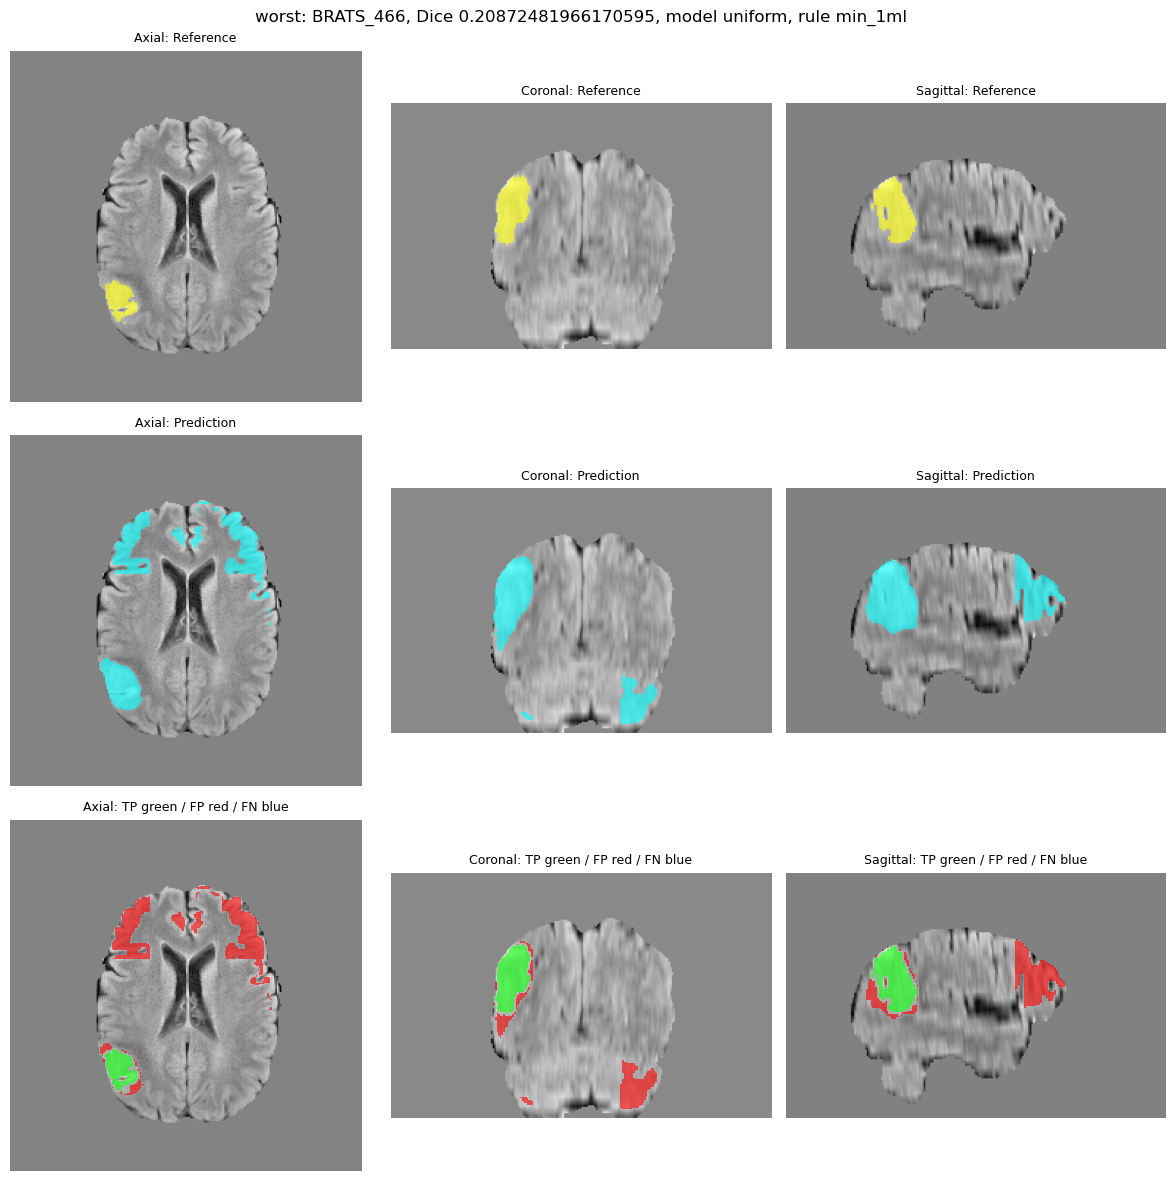

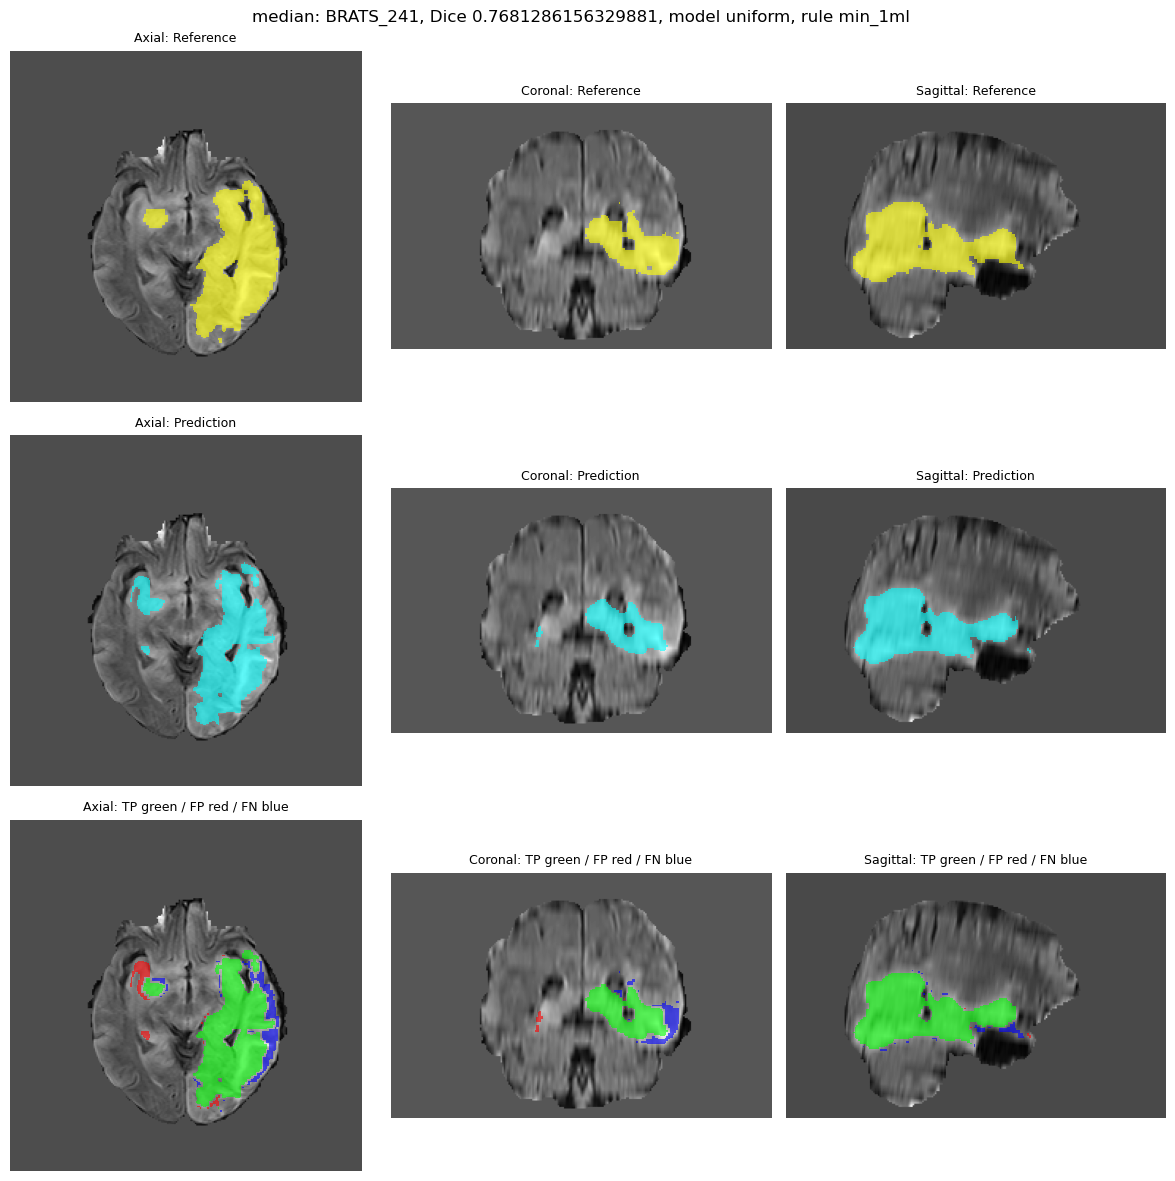

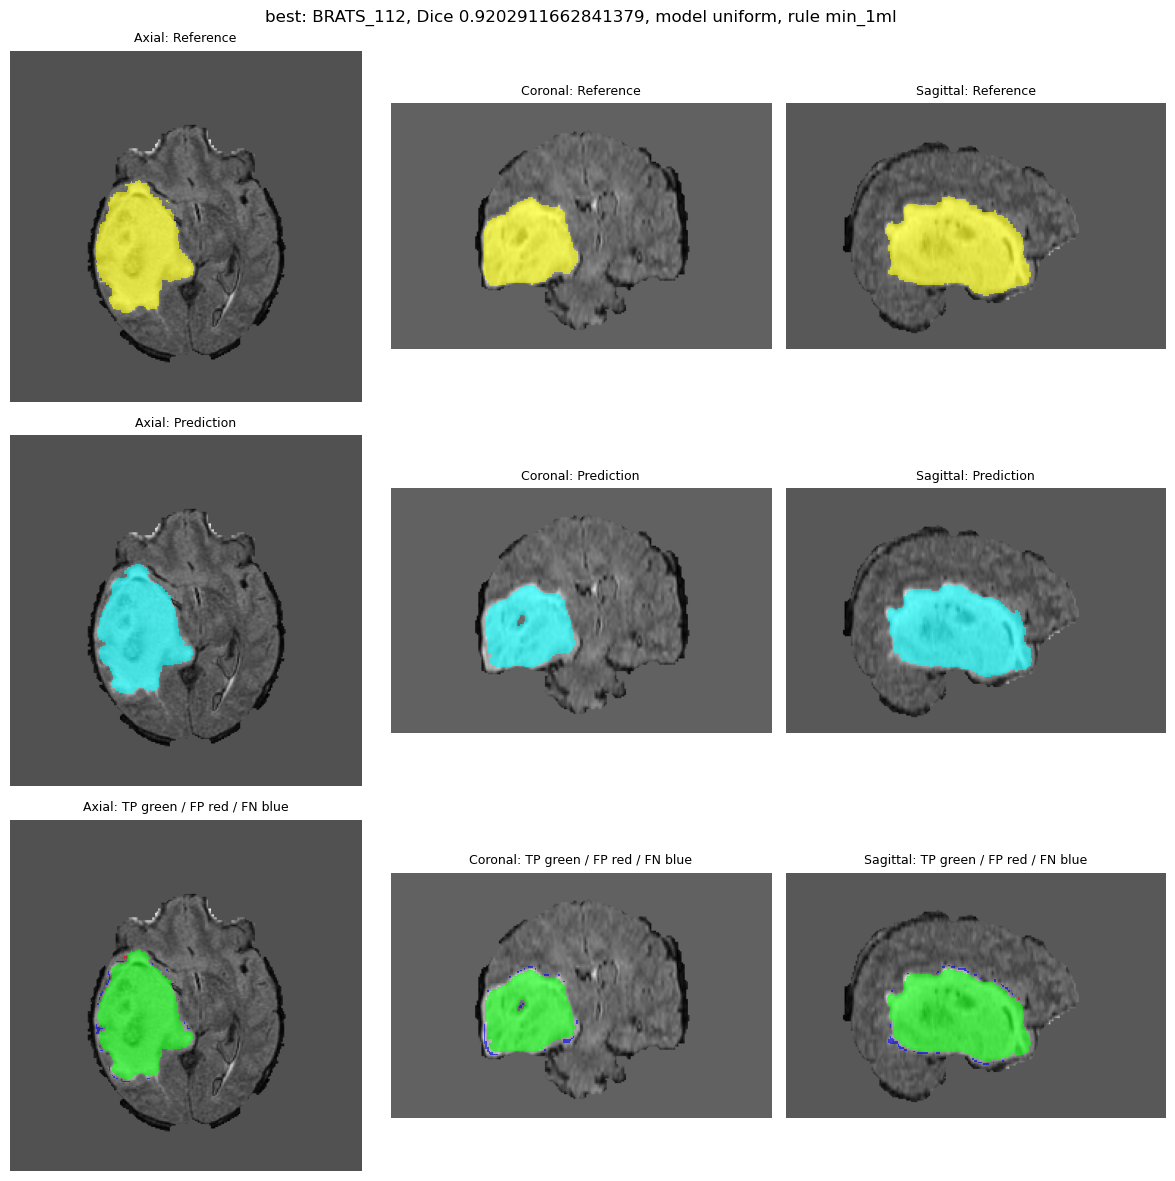

In [39]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
del slice
name, rule = "uniform", "min_1ml"      

d = pp_res[("test", name, rule)].sort_values("dice").reset_index(drop=True)
picks = {"worst": d.iloc[0], "median": d.iloc[len(d) // 2], "best": d.iloc[-1]}
ids = test_df["case_id"].tolist()

for tag, r in picks.items():
    cid = r["case"]
    probs, true, spacing = load_case(f"{name}_test_ov50", cid)
    pred = probs > 0.5
    if rule == "min_1ml" and pred.any():                      
        lab, n = label(pred)
        sizes = np.bincount(lab.ravel())[1:]
        pred = np.isin(lab, 1 + np.flatnonzero(sizes * np.prod(spacing) / 1000 >= 1.0))
    flair = test_dataset[ids.index(cid)][0][0].numpy()        

    cd, ch, cw = np.argwhere(true).mean(0).round().astype(int)   
    planes = {"Axial":    ((cd, slice(None), slice(None)), True),
              "Coronal":  ((slice(None), slice(None), cw), False),
              "Sagittal": ((slice(None), ch, slice(None)), False)}

    fig, ax = plt.subplots(3, 3, figsize=(12, 12))
    for j, (plane, (sl, transpose)) in enumerate(planes.items()):
        bg, t, p = flair[sl], true[sl], pred[sl]
        if transpose:
            bg, t, p = bg.T, t.T, p.T
        layers = [("Reference", [(t, "yellow")]),
                  ("Prediction", [(p, "cyan")]),
                  ("TP green / FP red / FN blue", [(p & t, "lime"), (p & ~t, "red"), (~p & t, "blue")])]
        for i, (title, masks) in enumerate(layers):
            ax[i, j].imshow(bg, cmap="gray", origin="lower")
            for m, colour in masks:
                ax[i, j].imshow(np.ma.masked_where(~m, m), cmap=ListedColormap([colour]), alpha=0.6, origin="lower")
            ax[i, j].set_title(f"{plane}: {title}", fontsize=9)
            ax[i, j].axis("off")
    fig.suptitle(f"{tag}: {cid}, Dice {r['dice']}, model {name}, rule {rule}")
    plt.tight_layout()
    plt.savefig(f"overlay_{tag}.png", dpi=150)
    plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

* Colour true-positive, false-positive and false-negative voxels distinctly. Relate at least one error to boundary
quality, small structures or patch context. 

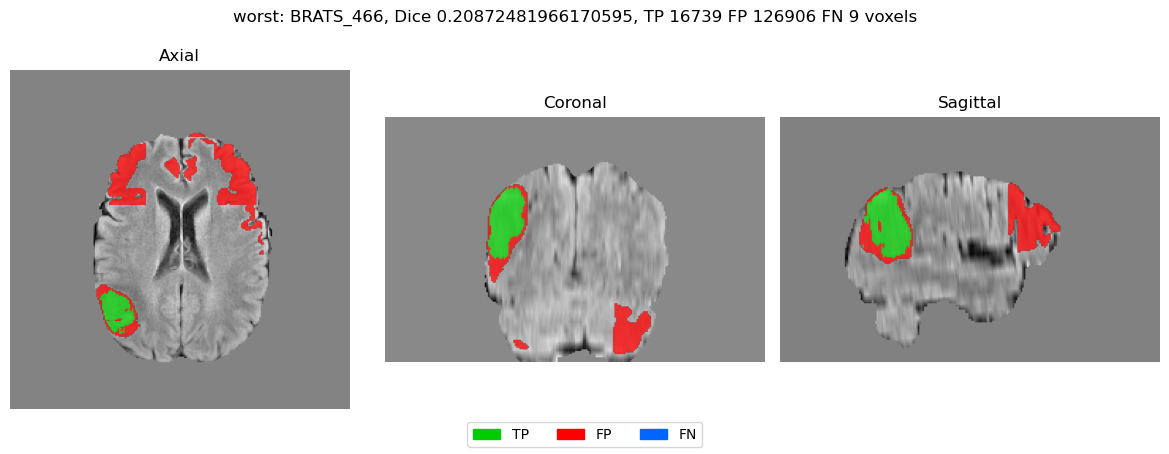

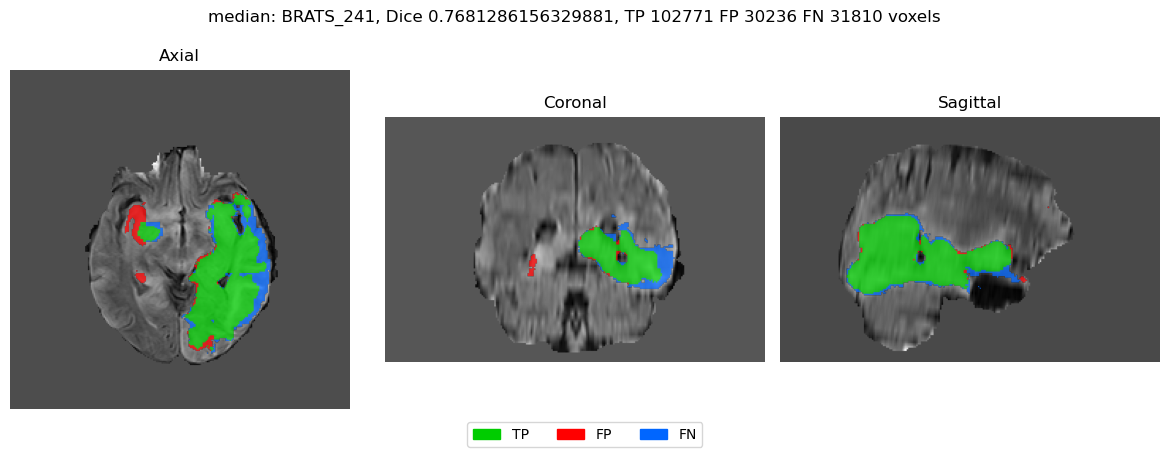

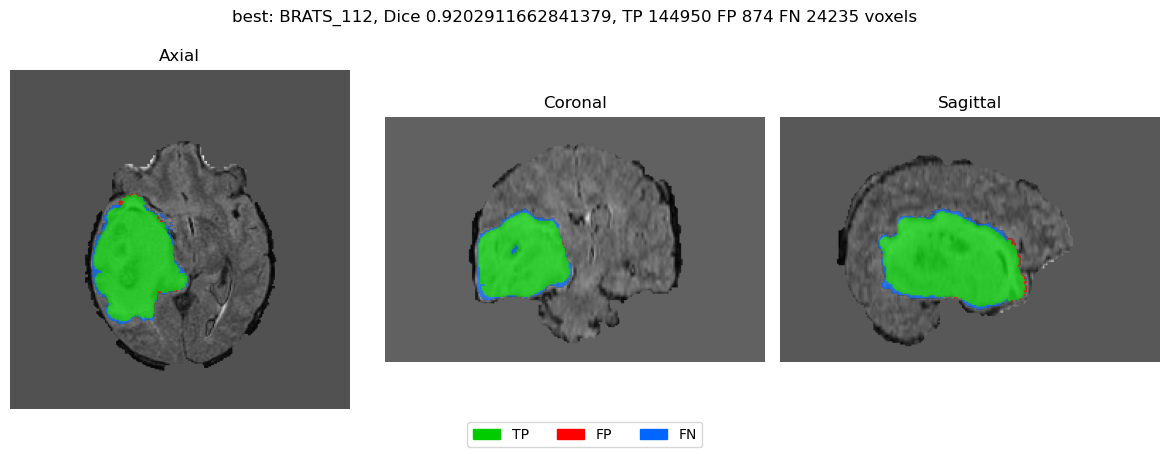

In [45]:
from matplotlib.patches import Patch

cols = {"TP": (0, 0.8, 0), "FP": (1, 0, 0), "FN": (0, 0.4, 1)}

for tag, r in picks.items():
    probs, true, spacing = load_case(f"{name}_test_ov50", r["case"])
    pred = probs > 0.5
    if rule == "min_1ml" and pred.any():                     
        lab, n = label(pred)
        sizes = np.bincount(lab.ravel())[1:]
        pred = np.isin(lab, 1 + np.flatnonzero(sizes * np.prod(spacing) / 1000 >= 1.0))
    flair = test_dataset[ids.index(r["case"])][0][0].numpy()
    cd, ch, cw = np.argwhere(true).mean(0).round().astype(int)

    views = {"Axial": ((cd, slice(None), slice(None)), True),
             "Coronal": ((slice(None), slice(None), cw), False),
             "Sagittal": ((slice(None), ch, slice(None)), False)}

    fig, ax = plt.subplots(1, 3, figsize=(12, 4.5))
    for a, (plane, (sl, T)) in zip(ax, views.items()):
        bg, t, p = flair[sl], true[sl], pred[sl]
        if T:
            bg, t, p = bg.T, t.T, p.T
        rgba = np.zeros((*bg.shape, 4))
        for m, c in [(p & t, "TP"), (p & ~t, "FP"), (~p & t, "FN")]:
            rgba[m] = (*cols[c], 0.75)
        a.imshow(bg, cmap="gray", origin="lower")
        a.imshow(rgba, origin="lower")
        a.set_title(plane); a.axis("off")

    tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()
    fig.suptitle(f"{tag}: {r['case']}, Dice {r['dice']}, TP {tp} FP {fp} FN {fn} voxels")
    fig.legend(handles=[Patch(color=cols[k], label=k) for k in cols], loc="lower center", ncol=3)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95))
    plt.savefig(f"errors_{tag}.png", dpi=150)
    plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

* Compare Dice with HD95 and volume error for these cases. Explain why one metric cannot summarize every
failure.

             case  dice    hd95  abs_err_ml  pct_err  true_ml
pick                                                         
best    BRATS_112  0.92    3.32       23.36   -13.81   169.18
median  BRATS_241  0.77   38.55        1.57    -1.17   134.58
worst   BRATS_466  0.21  118.83      126.90   757.68    16.75


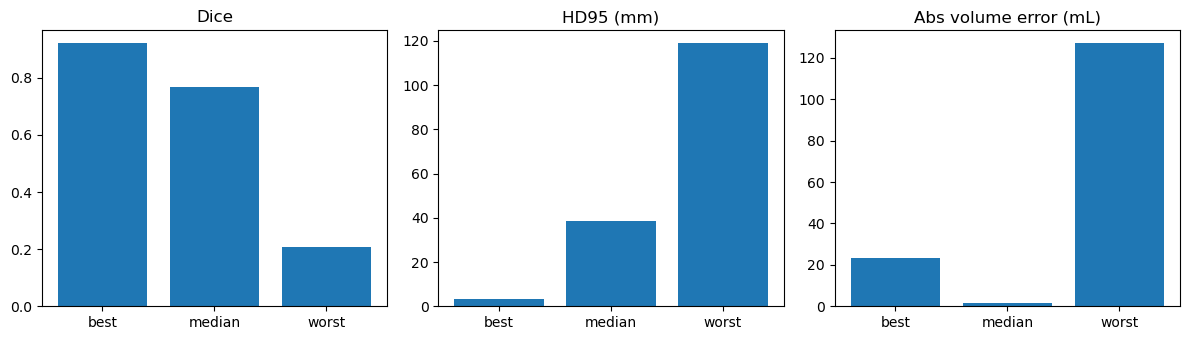

In [41]:
cmp = d[d["case"].isin([p["case"] for p in picks.values()])].copy()
cmp["pick"] = cmp["case"].map({p["case"]: k for k, p in picks.items()})
cmp["true_ml"] = cmp["true_vox"] * cmp["vox_mm3"] / 1000
cmp["pct_err"] = 100 * (cmp["pred_vox"] - cmp["true_vox"]) / cmp["true_vox"]
cmp = cmp.set_index("pick").loc[["best", "median", "worst"]]
print(cmp[["case", "dice", "hd95", "abs_err_ml", "pct_err", "true_ml"]].round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, col, title in zip(ax, ["dice", "hd95", "abs_err_ml"], ["Dice", "HD95 (mm)", "Abs volume error (mL)"]):
    a.bar(cmp.index, cmp[col]); a.set_title(title)
plt.tight_layout(); plt.show()

This is done in the report

------------------------------------------------------------------------------------------------------------------------------------------------

* State at least three limitations, including the small training budget and the lack of external-site validation.

This is done in the report

------------------------------------------------------------------------------------------------------------------------------------------------

# Bonus

1. Missing-modality stress test. Without retraining, replace each MRI channel in turn with zeros at test time.
Compare Dice, HD95 and volume error with the four-channel result. Identify the most influential channel,
explain why zeroing is an imperfect simulation of a genuinely missing acquisition, and state how training could
be redesigned for missing modalities.

In [ ]:
name = "uniform"                                  
ckpt = {"uniform": "model_uniform_best.pth", "aware": "model_aware_best.pth"}[name]
channels = ["FLAIR", "T1", "T1ce", "T2"]
n_cases = len(df)                                    
m = UNET().to(device)
m.load_state_dict(torch.load(ckpt, map_location=device))
m.eval()

rows = []
for i, (image, mask) in enumerate(test_dataloader):          
    if i >= n_cases:
        break
    true = mask[0].numpy() > 0.5
    spacing = nib.load(DATASET_PATH + test_df.iloc[i]["image_relpath"]).header.get_zooms()[:3]
    sp, vox = (spacing[2], spacing[0], spacing[1]), np.prod(spacing)

    for c in range(4):
        x = image.clone().to(device)
        x[:, c] = 0                                           
        pred = sliding_window_probs(m, x, PATCH, 0.5).numpy() > 0.5

        tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()
        if pred.any() and true.any():
            ps, ts = binary_erosion(pred) ^ pred, binary_erosion(true) ^ true
            hd = np.percentile(np.concatenate([distance_transform_edt(~ts, sampling=sp)[ps],
                                               distance_transform_edt(~ps, sampling=sp)[ts]]), 95)
        else:
            hd = np.nan
        rows.append(dict(case=test_df.iloc[i]["case_id"], zeroed=channels[c],
                         dice=2*tp / max(2*tp + fp + fn, 1), hd95=hd,
                         abs_err_ml=abs(pred.sum() - true.sum()) * vox / 1000,
                         pct_err=100 * (pred.sum() - true.sum()) / true.sum()))


res = pd.DataFrame(rows)
base = test_res[name][test_res[name]["case"].isin(res["case"])].copy()
base["zeroed"] = "none"
base["abs_err_ml"] = (base["pred_vox"] - base["true_vox"]).abs() * base["vox_mm3"] / 1000
base["pct_err"] = 100 * (base["pred_vox"] - base["true_vox"]) / base["true_vox"]
allr = pd.concat([base[res.columns], res])

summary = allr.groupby("zeroed").agg(dice=("dice", "mean"), hd95_median=("hd95", "median"),
                                     abs_err_ml=("abs_err_ml", "mean"),
                                     abs_pct_err=("pct_err", lambda s: s.abs().mean()))
summary = summary.loc[["none"] + channels]
summary["dice_drop"] = summary.loc["none", "dice"] - summary["dice"]
print(summary.round(3))

summary[["dice", "hd95_median", "abs_err_ml"]].plot.bar(subplots=True, layout=(1, 3), figsize=(12, 3.5), legend=False)
plt.tight_layout(); plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

2. Sliding-window seam test. Run the same trained model with 0%, 25% and 50% overlap. Compare runtime
and metrics, then plot the probability difference near patch borders. Explain when overlap helps and why
selecting overlap after repeatedly inspecting the test labels would bias the result.

overlap 0.0: stride 96, starts D [0, 59], H/W [0, 96, 144], windows 18
overlap 0.25: stride 72, starts D [0, 59], H/W [0, 72, 144], windows 18
overlap 0.5: stride 48, starts D [0, 48, 59], H/W [0, 48, 96, 144], windows 48
         sec_per_case   dice   sens  hd95_median  abs_err_ml
overlap                                                     
0.00            3.658  0.637  0.672       47.896      47.796
0.25            3.729  0.690  0.657       38.259      43.784
0.50           10.147  0.714  0.667       18.493      42.942


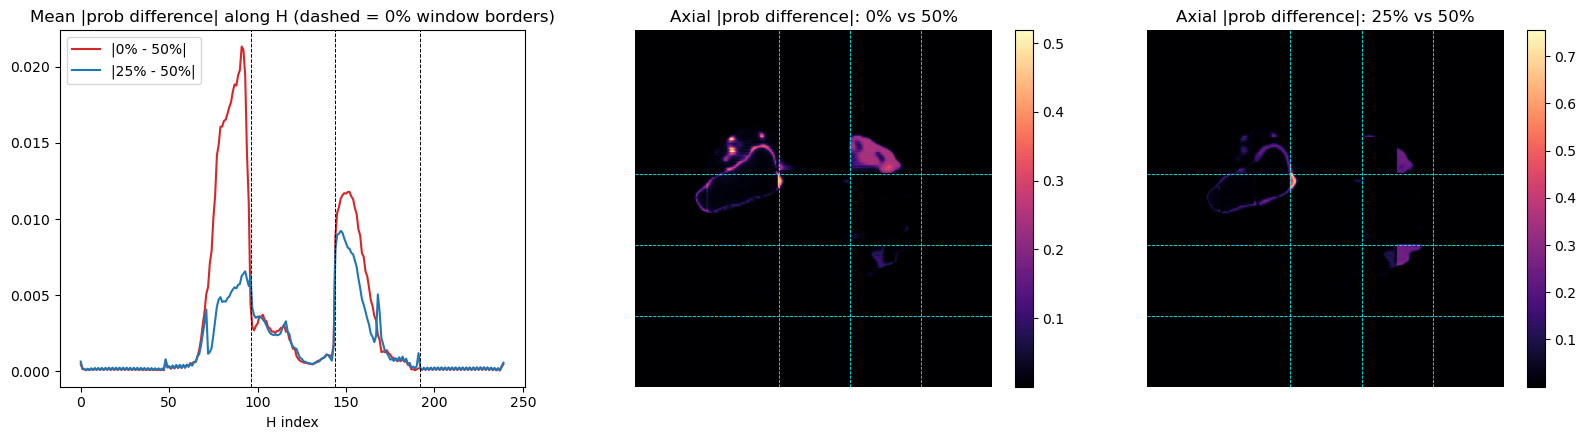

In [ ]:
name = "uniform"                                  
ckpt = {"uniform": "model_uniform_best.pth", "aware": "model_aware_best.pth"}[name]
loader, df = test_dataloader, test_df            
overlaps = [0.0, 0.25, 0.5]
n_cases = len(df)                                   

m = UNET().to(device)
m.load_state_dict(torch.load(ckpt, map_location=device))
m.eval()


for ov in overlaps:
    s = int(round(PATCH * (1 - ov)))
    print(f"overlap {ov}: stride {s}, starts D {window_starts(155, PATCH, s)}, "
          f"H/W {window_starts(240, PATCH, s)}, windows {len(window_starts(155, PATCH, s)) * len(window_starts(240, PATCH, s))**2}")

rows, keep = [], {}
for i, (image, mask) in enumerate(loader):                   
    if i >= n_cases:
        break
    true = mask[0].numpy() > 0.5
    spacing = nib.load(DATASET_PATH + df.iloc[i]["image_relpath"]).header.get_zooms()[:3]
    sp, vox = (spacing[2], spacing[0], spacing[1]), np.prod(spacing)
    x = image.to(device)

    for ov in overlaps:
        t0 = time.time()
        probs = sliding_window_probs(m, x, PATCH, ov).numpy()
        secs = time.time() - t0
        pred = probs > 0.5
        if i == 0:
            keep[ov], true0 = probs, true                    # kept for the seam plot

        tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()
        if pred.any() and true.any():
            ps, ts = binary_erosion(pred) ^ pred, binary_erosion(true) ^ true
            hd = np.percentile(np.concatenate([distance_transform_edt(~ts, sampling=sp)[ps],
                                               distance_transform_edt(~ps, sampling=sp)[ts]]), 95)
        else:
            hd = np.nan
        rows.append(dict(case=df.iloc[i]["case_id"], overlap=ov, seconds=secs,
                         dice=2*tp / max(2*tp + fp + fn, 1), sens=tp / max(tp + fn, 1), hd95=hd,
                         abs_err_ml=abs(pred.sum() - true.sum()) * vox / 1000))

seam = pd.DataFrame(rows)
summary = seam.groupby("overlap").agg(sec_per_case=("seconds", "mean"), dice=("dice", "mean"),
                                      sens=("sens", "mean"), hd95_median=("hd95", "median"),
                                      abs_err_ml=("abs_err_ml", "mean"))
print(summary.round(3))


hs = window_starts(240, PATCH, PATCH)                       
borders = sorted(set(hs + [s + PATCH for s in hs]) - {0, 240})
cd = int(np.argwhere(true0)[:, 0].mean().round())            

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for ov, colour in [(0.0, "tab:red"), (0.25, "tab:blue")]:
    diff = np.abs(keep[ov] - keep[0.5])                      
    ax[0].plot(diff.mean(axis=(0, 2)), color=colour, label=f"|{int(ov*100)}% - 50%|")
for b in borders:
    ax[0].axvline(b, color="k", ls="--", lw=0.7)
ax[0].set_title("Mean |prob difference| along H (dashed = 0% window borders)")
ax[0].set_xlabel("H index"); ax[0].legend()

for a, ov in zip(ax[1:], [0.0, 0.25]):
    im = a.imshow(np.abs(keep[ov] - keep[0.5])[cd], cmap="magma")
    for b in borders:
        a.axhline(b, color="cyan", lw=0.6, ls="--"); a.axvline(b, color="cyan", lw=0.6, ls="--")
    a.set_title(f"Axial |prob difference|: {int(ov*100)}% vs 50%"); a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------